# Teste de Hipótese 

### Monstro: Beholder

Autor: **Carlos Gabriel de Oliveira Campos**

Professor: Dr. **Daniel Roberto Cassar**

O teste de hipótese é uma ferramenta estatística que compara duas ideias opostas sobre um grupo de pessoas ou coisas e usa dados sobre uma amostra desse grupo para decidir qual ideia é mais provável. Os dados amostrais são então coletados e estudados para verificar se a afirmação é correta. Para melhor compreender essa técnica, fazem-se necessários os seguinte conceitos:

Significância $(\alpha)$: O máximo de probabilidade tolerável para erroneamente rejeitar a afirmação (erro tipo 1), geralmente definido como 5% [1].

P-valor: Fração de estatísticas de teste de uma simulação tão ou mais extremos do que observado. Se ela for menor do que $\alpha$, então a hipótese nula é rejeitada.

___


## Contextualização

A confirmação da teoria da Relatividade Geral de Albert Einstein durante o eclipse 
solar de 1919 é um momento marcante na história da ciência. O experimento, conduzido 
por Sir Arthur Eddington, tinha como objetivo testar uma das principais previsões da 
Relatividade Geral: a curvatura da luz pela gravidade.
A Teoria Geral da Relatividade de Einstein, publicada em 1915, introduziu uma 
nova compreensão da gravidade. Em vez da visão clássica da gravidade como uma força, 
a teoria de Einstein propôs que objetos massivos, como o Sol, deformam o tecido do 
espaço‑tempo ao seu redor. A luz que passa perto de um objeto massivo destes seguiria 
um caminho curvo devido a essa distorção, criando o efeito de lente gravitacional.
A teoria de Einstein previu que, durante um eclipse solar, quando a massa do Sol 
bloqueasse a luz de estrelas distantes, as posições dessas estrelas pareceriam deslocadas 
devido ao campo gravitacional do Sol. As posições observadas das estrelas seriam 
diferentes de suas posições esperadas se a gravidade não afetasse a luz. Especificamente, 
as posições das estrelas seriam deslocadas para fora do Sol.
Os resultados esperados do experimento envolviam a medição do deslocamento 
angular das estrelas quando elas apareciam perto do Sol durante um eclipse solar total. 
O deslocamento angular seria a diferença entre a posição aparente de uma estrela e sua 
posição real na ausência da gravidade do Sol.
A teoria de Einstein previu que esse deslocamento angular seria de aproximadamente 
1.75 segundo de arco (arcseg) para estrelas que estivessem próximas ao Sol durante 
o eclipse.
Arthur Eddington organizou duas expedições (uma para Sobral, no Brasil, e outra 
para a Ilha do Príncipe, na África Ocidental) para observar o eclipse solar total de 29 
de maio de 1919. As equipes tiraram fotografias das estrelas que estavam próximas ao 
Sol durante o eclipse.
As fotografias tiradas durante o eclipse foram comparadas com fotografias do mesmo 
campo estelar tiradas quando o Sol não estava nas proximidades. As posições observadas 
das estrelas foram de fato deslocadas para fora do Sol, de acordo com as previsões de 
Einstein.

## Função de suporte 

Para plotar o histograma das medições simuladas de maneira mais informativa, fiz algumas adaptações na função de suporte desenvolvida pelo professor Daniel, conforme [2].

In [2]:
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import seaborn as sns


def histograma_desloc(resultado, estatistica_observada, val_critico=None, xlabel_alt=False):
    eixo = sns.histplot(
        resultado,
        stat="probability",
        bins=20,
    )

    cor_normal = eixo.patches[0].get_facecolor()
    cor_destaque = "orange"

    for barra in list(eixo.patches):
        x_esq = barra.get_x()
        x_dir = x_esq + barra.get_width()
        altura = barra.get_height()

        if x_dir <= estatistica_observada:
            pass

        elif x_esq >= estatistica_observada:
            barra.set_facecolor(cor_destaque)

        else:
            barra.set_width(estatistica_observada - x_esq)

            retangulo_laranja = plt.Rectangle(
                (estatistica_observada, 0),
                x_dir - estatistica_observada,
                altura,
                facecolor=cor_destaque,
                edgecolor=barra.get_edgecolor(),
                linewidth=barra.get_linewidth(),
            )
            eixo.add_patch(retangulo_laranja)

    eixo.axvline(estatistica_observada, color="red", linestyle="-")

    legendas = [
        mpatches.Patch(
            facecolor=cor_normal,
            label="Valores menores que a medida observada",
        ),
        mpatches.Patch(
            facecolor=cor_destaque,
            label="Valores maiores que a medida observada",
        ),
        mlines.Line2D(
            [], [], color="red", linestyle="-", label="Medida observada"
        ),
    ]

    if val_critico:
        eixo.axvline(val_critico, color="green", linestyle="-")
        legendas.append(
                    mlines.Line2D(
            [], [], color="green", linestyle="-", label="Valor crítico"
            )
        )


    # Altura baseada nas barras reais geradas
    altura_maxima = max(barra.get_height() for barra in eixo.patches)
    eixo.set_ylim(bottom=0, top=altura_maxima * 1.35)

    xlabel = "Deslocamento angular simulado (arcseg)"
    
    if xlabel_alt:
        xlabel = "Valor Padronizado"
        
    eixo.set(
        xlabel=xlabel,
        ylabel="Probabilidade"
    )
    # loc="upper left" posiciona a legenda longe da linha em x = 1.98
    eixo.legend(handles=legendas, loc="upper left")

## Exercício

> Suponha que pelo modelo de Einstein e pelos equipamentos utilizados, o valor esperado para o deslocamento angular segue uma distribuição normal $\mathcal{N}(1.75,0.02)$ (isto é, tem média de 1.75 e variância de 0.02). Proponha e execute um teste de hipótese para testar o modelo de Einstein à luz do resultado obtido, usando de simulação, sabendo que **o deslocamento angular medido das estrelas durante o eclipse de 1919 
foi de aproximadamente 1.98 arcseg**.

Para este problema, podemos formular nossa **hipótese nula** $H_0$ de forma que o deslocamento angular segue a distribuição conforme a teoria da relatividade, ou seja, $X \sim \mathrm{Normal}(1.75,0.02)$. Ademais, será adotado um valor de 95% para o nível de confiança, uma vez que este é o padrão geral na ciência, e não há condições especiais particulares a essa questão para mudá-lo [3].  

In [3]:
NIVEL_CONFINACA = 0.95
SIGNIFICANCIA = 1 - NIVEL_CONFINACA # 0.05

## Realizando a simulação

Vamos gerar uma simulação com 10 milhões de valores para o deslocamento angular, de modo que eles seguem a distribuição proposta.

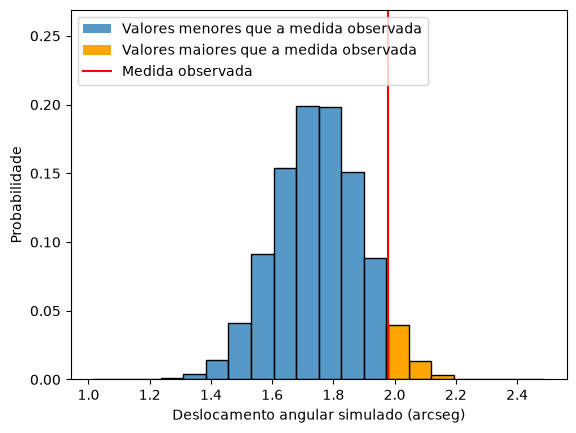

In [4]:
# Configurando semente aleatória
np.random.seed(42)

# Informações para a simulação
NUM_SIM = 10_000_000
VAL_MEDIA = 1.75

VARIANCIA = 0.02
DESV_PADRAO = VARIANCIA ** (1/2)

VAL_MEDIDO = 1.98

# Gerando 10 milhão de valores
desloc_simulados = np.random.normal(loc=VAL_MEDIA, scale=DESV_PADRAO, size=NUM_SIM)

histograma_desloc(desloc_simulados, VAL_MEDIDO)

Vamos verificar as estatísticas da simulação

In [5]:
print(
    f"Média: {desloc_simulados.mean()}\n" +
    f"Variância: {desloc_simulados.var()}"
    )

Média: 1.7499909550413817
Variância: 0.020000543262427724


Como esperado de acordo com a Lei dos Grandes Números, o grande volume da simulação nos proporcionou uma boa aproximação em relação à distribuição original. Assim, é razoável interpretá-la de modo que apresente, mesmo que aproximadamente, um eixo de simetria ao redor da média (1.75 arcseg).
 
Nesse caso, o valor medido de 1.98 arcseg foi de 0.23 arcseg maior do que a média, de acordo com $H_0$. A partir de sua simetria, podemos afirmar que essa medida está tão "distante" de $H_0$ como uma medida 0.23 arcseg *abaixo da média* (1.52 arcseg). Dessa maneira, o material em [2] nos auxilia a compreender o cálculo do p-valor, definido como

$$
\textrm{p-valor} = P(X \leq 1.52 | H_0) + P(X \geq 1.98 | H_0)
$$

Se $H_0$ é verdadeira, então a variável $X$ deve serguir a **distribuição normal** com média em 1.75 e variância de 0.02:

$$
\textrm{p-valor} = P(X \leq 1.52 | X \sim \mathrm{Normal}(1.75,0.02)) + P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)).
$$

Uma forma de calcular estas probabilidades é pela cdf da distribuição Normal:


$$
P(X \leq 1.52 | X \sim \mathrm{Normal}(1.75,0.02)) = F(1.52| 1.75, 0.02)
$$


$$
P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)) = 1 - F(1.98| 1.75, 0.02)
$$


Tendo organizado as fórmulas, vamos partir para o cálculo do p-valor:

In [6]:
contador = 0
for desloc in desloc_simulados:
    if 1.52 < desloc < 1.98:
        continue
    contador += 1
print(
    f"p-valor calculado: {contador / NUM_SIM}" +
    "\n\n" +
    f"Conclusão do teste de hipótese: \x1b[32mnão devemos rejeitar H0\x1b[0m!"
    )

p-valor calculado: 0.1038591

Conclusão do teste de hipótese: não devemos rejeitar H0!


Logo, temos que o p-valor calculado é maior do que a significância estipulada previamente! Portanto, não devemos rejeitar $H_0$, a qual afirma que o deslocamento angular das estrelas segue a distribuição normal $\mathcal{N}(1.75,0.02)$.

## Conclusão

O teste de hipótese, aliado aos conceitos de significância e de p-valor, mostrou-se como uma ferramenta útil para a validação de modelos, como no caso explorado nesta atividade, da Teoria da Relatividade Geral de Einstein a partir do cálculo do deslocamento angular de estrelas. Nesse contexto, o p-valor nos guiou de modo que não rejeitemos a hipótese nula elaborada, validando o modelo do cientista.

## Apêndice: Z-score

Outra possível abordagem para realizar o teste de hipótese parte da padronização *z*, mais conhecida em inglês como *z-score*, que é definida como

$$
z = \frac{x - \mu}{\sigma}
$$

Em que $\mu$ e $\sigma$ representam a média e o desvio padrão da nossa distribuição, respectivamnte, e $x$, o valor observado. Vamos calculá-lo, dado que $x = 1.98$, $\mu = 1.75$ e $\sigma = \sqrt{0.02}$:

In [7]:
z_score = (VAL_MEDIDO - VAL_MEDIA) / DESV_PADRAO
print(f"Valor do z_score: {z_score:.3f}")

Valor do z_score: 1.626


Isso significa que o valor medido de 1.98 está aproximadamente a 1.63 desvios padrão da média da distribuição. Mas o que fazer com esse valor?

Para isso, é necessário analisar a *distribuição normal padrão*! Ela consiste em uma distribuição normal qualquer, mas que foi padronizada. Assim, a nova distribuição apresenta média de 0 e desvio padrão de 1 (adimensional), sendo que é descrita como $\mathcal{N}(0,1)$. Vejamos: 

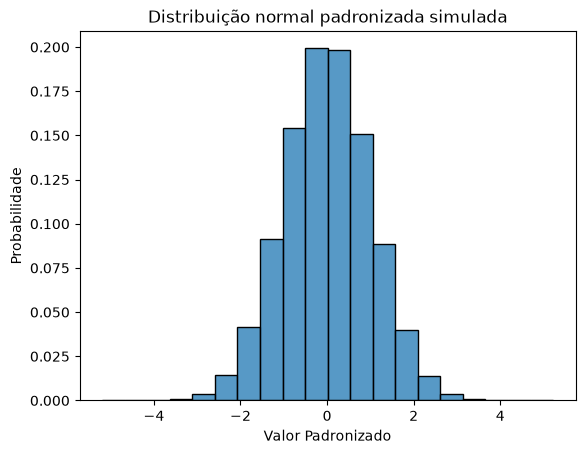

In [8]:
# Gera distribuição padronizada e ordena
dist_padronizada = (desloc_simulados - VAL_MEDIA) / DESV_PADRAO
dist_padronizada = sorted(dist_padronizada)

# Plota distribuição
eixo = sns.histplot(
        dist_padronizada,
        stat="probability",
        bins=20,
    )
    # Configura os rótulos dos eixos
eixo.set(
    xlabel="Valor Padronizado",
    ylabel="Probabilidade",
    title="Distribuição normal padronizada simulada"
);

Nesse contexto, o *valor crítico* pode ser compreeendido como o ponto da distribuição da estatística de teste sob a hipótese nula que define o conjunto de valores que justificam a rejeição da hipótese nula [4, tradução própria]. 

No nosso caso, há dois valores críticos, uma vez que estamos analisando as duas caudas da distribuição. Logo, o valor crítico é determinado a partir do grau de significância que atribuímos no início deste problema, de 5%. Como a distribuição é simétrica, o valor crítico pode ser estimado de acordo com o valor do ponto no percentil 2.5. Além disso, a média em 0 dessa distribuição faz com que os dois valores críticos tenham o mesmo módulo. Vamos encontrá-lo!

In [9]:
valor_critico = 0
for n, valor in enumerate(sorted(dist_padronizada)):
    # 
    if n == 249_999:
        valor_critico = abs(valor)
        break   
print(f"Módulo do valor crítico: {valor_critico}")

Módulo do valor crítico: 1.9597900412911702


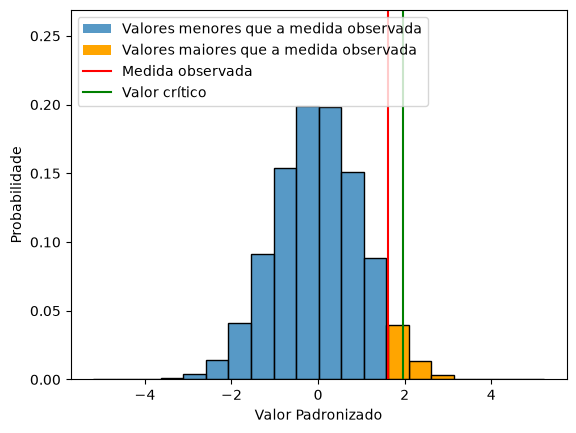

In [11]:
histograma_desloc(dist_padronizada, z_score, val_critico=valor_critico, xlabel_alt=True)

Portanto, o valor crítico pode ser arredondado para $\pm 1.96$. Dessa forma, podemos aplicar um raciocínio análogo ao primeiro teste de hipótese para concluir que dado que $1.63 < 1.96$, implicando que o valor observado está mais próximo de $H_0$ do que o ponto crítico está. Logo, nos é permitido não rejeitar a hipótese nula! 

## Referências

[1] **Hypothesis Testing**. GeeksforGeeks, 18 mar. 2026. Disponível em: https://www.geeksforgeeks.org/data-science/understanding-hypothesis-testing/. Acesso em: 13 out. 2026.

[2] CASSAR, Daniel R. Material de aula **LMA-203 8.0 - Introdução aos testes de hipótese** para a disciplina de Estatística, 2026.

[3] **What Percentage Is Statistically Significant: 5% and Beyond**. ScienceInsights, 18 mar. 2026. Disponível em: https://scienceinsights.org/what-percentage-is-statistically-significant-5-and-beyond/. Acesso em: 13 out. 2026.

[4] MINITAB. What is a critical value? In: **Minitab Support**, 2026. Disponível em: https://support.minitab.com/en-us/minitab/help-and-how-to/statistics/basic-statistics/supporting-topics/basics/what-is-a-critical-value/. Acesso em: 20 out. 2026.

## Uso de IA neste trabalho

A ferramente de inteligência artificial Gemini foi utilizada para auxiliar a:

- Pegar a intuição de testes de hipótese;
- Plotar gráficos;
- Gerar a simulação;
- Esclarecer o uso z-score no contexto de teste de hipótese;
- Revisar o trabalho.

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/rodape_eleicao.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>